# Commerce Intelligence Platform - analysis walkthrough

End-to-end analytics on the **Olist Brazilian marketplace** (99K orders, 3K sellers, 8K seller leads, 2016-2018).
This notebook reads the dbt-built DuckDB warehouse and walks through each analysis with the SQL / code that produced it.
Run `make all` first (or at least `make warehouse analyze`). Window: **Jan-2017 to Jul-2018** (complete months). Currency BRL.

Sections: 1 Warehouse · 2 KPIs · 3 Retention · 4 RFM & CLV · 5 Delivery -> reviews · 6 Late-delivery risk model · 7 Sellers · 8 Seller acquisition funnel · 9 Geography · 10 Forecast · 11 Recommendations & experiments

In [1]:
import json, sys, warnings
sys.path.insert(0, "../src")
warnings.filterwarnings("ignore")
import pandas as pd, numpy as np
from IPython.display import Image, display, Markdown
from commerce_intel.db import connect, query, query_file
from commerce_intel.config import FIG_DIR, TABLE_DIR, RESULTS_JSON
pd.set_option("display.float_format", lambda v: f"{v:,.3f}")
con = connect()
R = json.loads(RESULTS_JSON.read_text())
fig = lambda name: display(Image(filename=str(FIG_DIR / f"{name}.png"), width=900))
tbl = lambda name: pd.read_csv(TABLE_DIR / f"{name}.csv")
print("warehouse tables:", query(con, "select count(*) n from information_schema.tables where table_schema='marts'").n.iloc[0])

warehouse tables: 10


## 1. Warehouse
dbt builds 10 staging views and 10 marts (5 dimensions, 4 facts, 1 one-big-table) with 59 tests. A few contracts worth seeing:

In [2]:
display(query(con, '''
select 'fact_orders' t, count(*) rows, count(distinct order_id) keys from marts.fact_orders union all
select 'dim_customer', count(*), count(distinct customer_unique_id) from marts.dim_customer union all
select 'fact_order_items', count(*), count(distinct order_id || '-' || order_item_id) from marts.fact_order_items union all
select 'fact_seller_funnel', count(*), count(distinct mql_id) from marts.fact_seller_funnel'''))
display(query_file(con, "13_data_quality_checks.sql"))

,t,rows,keys
0,fact_orders,99441,99441
1,dim_customer,96096,96096
2,fact_order_items,112650,112650
3,fact_seller_funnel,8000,8000


,check_name,n
0,orders missing delivery date while status=deli...,8
1,orders with no items (cancelled/unavailable),775
2,orders with no payment record,4
3,orders with no review,768
4,products with no category,610
5,zip prefixes without exact coordinates,163
6,payment total differs from GMV by > R$1,249


## 2. Executive KPIs

| GMV | Orders | Customers | AOV | YoY GMV (Jan-Jul) | Late rate | Avg review | Repeat customers |
|---|---|---|---|---|---|---|---|
| R$14.78M | 92,580 | 89,503 | R$160 | +160% | 6.8% | 4.08 | 3.0% |

,purchase_month,gmv,orders,buyers,active_sellers,aov,gmv_mom,gmv_yoy,cumulative_gmv
11,2017-12,"863,547.230",5673,5603,858,152.221,-0.268,NaN,"7,142,672.430"
12,2018-01,"1,107,301.890",7269,7166,963,152.332,0.282,7.071,"8,249,974.320"
13,2018-02,"986,908.960",6728,6569,945,146.687,-0.109,2.447,"9,236,883.280"
14,2018-03,"1,155,126.820",7211,7115,996,160.190,0.170,1.674,"10,392,010.100"
15,2018-04,"1,159,698.040",6939,6882,1118,167.128,0.004,1.812,"11,551,708.140"
16,2018-05,"1,149,781.820",6873,6814,1108,167.290,-0.009,0.961,"12,701,489.960"
17,2018-06,"1,022,677.110",6167,6128,1162,165.831,-0.111,1.033,"13,724,167.070"
18,2018-07,"1,058,728.030",6292,6230,1254,168.266,0.035,0.810,"14,782,895.100"


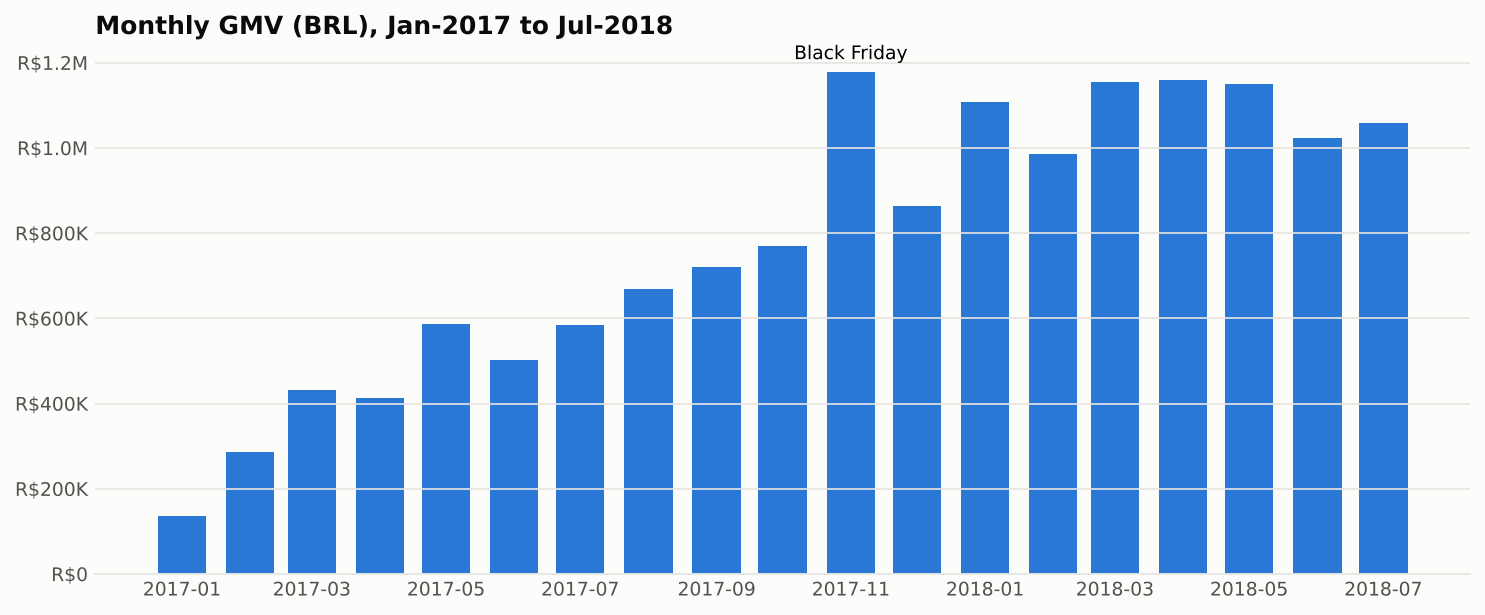

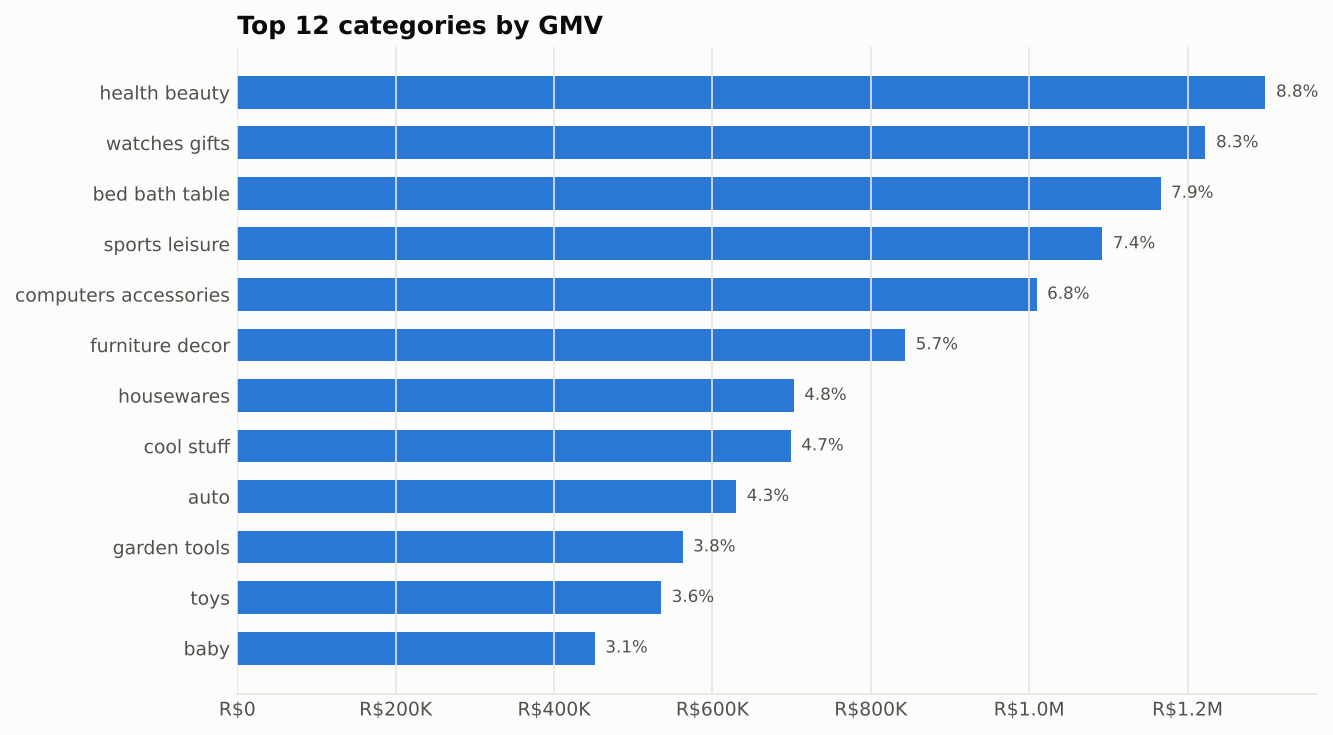

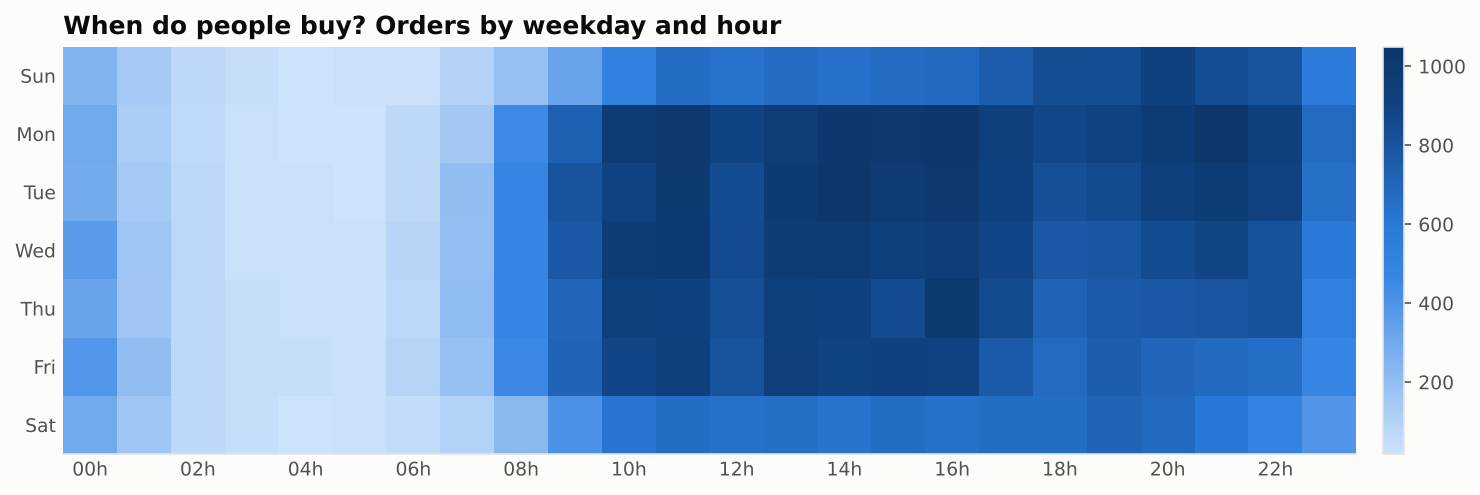

In [3]:
k = R["kpis"]
display(Markdown(f'''| GMV | Orders | Customers | AOV | YoY GMV (Jan-Jul) | Late rate | Avg review | Repeat customers |
|---|---|---|---|---|---|---|---|
| R${k["gmv_total"]/1e6:.2f}M | {k["orders"]:,} | {k["customers"]:,} | R${k["aov"]:.0f} | {k["gmv_yoy_ytd"]:+.0%} | {k["late_rate"]:.1%} | {k["avg_review"]:.2f} | {R["retention"]["repeat_customer_rate"]:.1%} |'''))
display(query_file(con, "01_monthly_kpis.sql").tail(8))
fig("01_monthly_gmv"); fig("03_category_gmv"); fig("04_orders_heatmap")

## 3. Retention and repeat purchase
Cohort = month of first order. Cells beyond the observable window are masked.

repeat-customer rate 3.04% | repeat-order GMV share 3.04% | avg month-1 retention 0.48% | month-6 0.26%
median days to 2nd order 25 | same-day 'second orders' (split checkouts) 32%


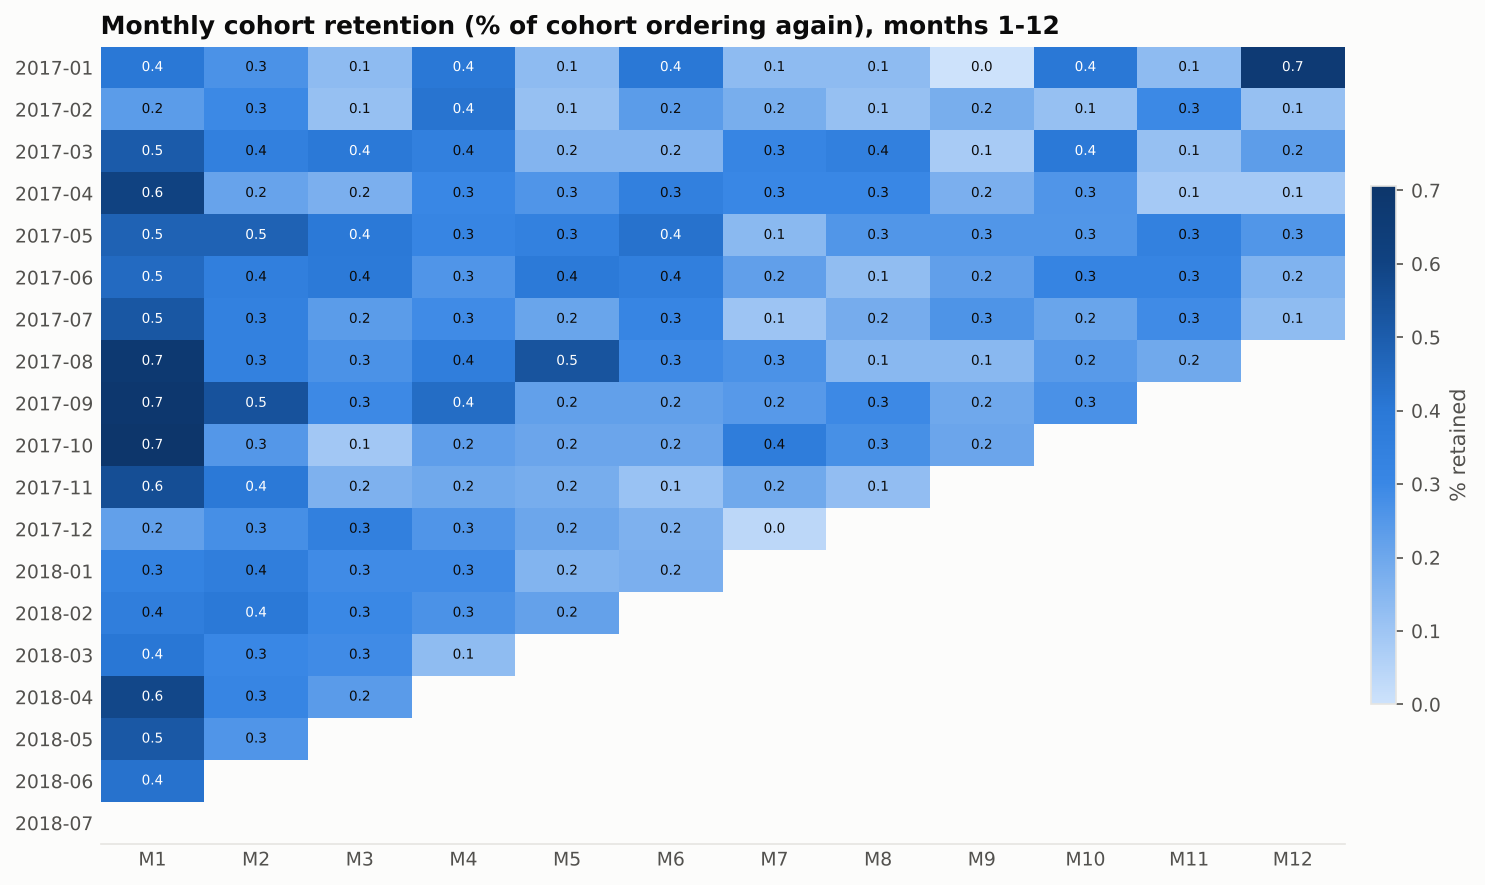

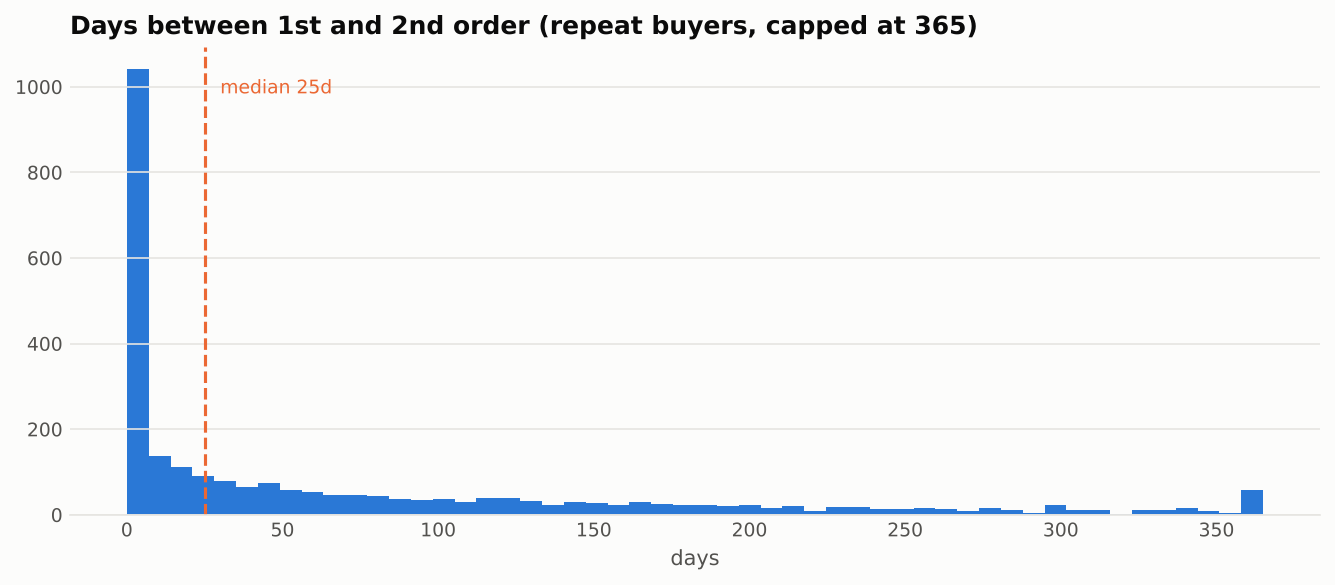

,category,customers,repeat_rate
0,home_appliances,689,0.091
1,fashion_bags_accessories,1733,0.059
2,NaN,708,0.056
3,furniture_decor,6031,0.047
4,bed_bath_table,8870,0.045
5,sports_leisure,7365,0.039
6,computers_accessories,6445,0.030
7,garden_tools,3381,0.030


In [4]:
r = R["retention"]
print(f"repeat-customer rate {r['repeat_customer_rate']:.2%} | repeat-order GMV share {r['repeat_order_gmv_share']:.2%} | "
      f"avg month-1 retention {r['month1_retention_avg']:.2%} | month-6 {r['month6_retention_avg']:.2%}")
print(f"median days to 2nd order {r['median_days_to_2nd_order']:.0f} | same-day 'second orders' (split checkouts) {r['share_2nd_order_same_day']:.0%}")
fig("05_cohort_retention"); fig("06_days_to_second_order")
display(tbl("retention_repeat_by_first_category").head(8))

## 4. RFM segmentation, K-means and CLV
Rules are tuned to a base where 97% of customers have one order. CLV uses BG/NBD for purchase frequency; Gamma-Gamma's shape parameter came out < 1 (undefined mean) so expected order value uses empirical-Bayes shrinkage instead - see `docs/methodology.md`.

,segment,customers,gmv,avg_monetary,avg_frequency,median_recency,avg_review,customer_share,gmv_share,gmv_index
0,Lapsed High-Value,12968,"4,042,853.580",311.756,1.000,362.000,4.098,0.147,0.275,1.879
1,High-Value New,6566,"2,963,123.590",451.283,1.000,87.000,3.954,0.074,0.202,2.719
2,Promising,27658,"2,688,519.120",97.206,1.000,88.000,4.133,0.313,0.183,0.586
3,Need Attention,17141,"2,599,736.650",151.668,1.000,204.000,4.018,0.194,0.177,0.914
4,Hibernating,21474,"1,565,342.370",72.895,1.000,365.000,4.175,0.243,0.107,0.439
5,At Risk,1516,"451,127.490",297.578,2.083,284.000,4.133,0.017,0.031,1.793
6,Champions,1175,"376,030.430",320.026,2.148,84.000,4.169,0.013,0.026,1.928


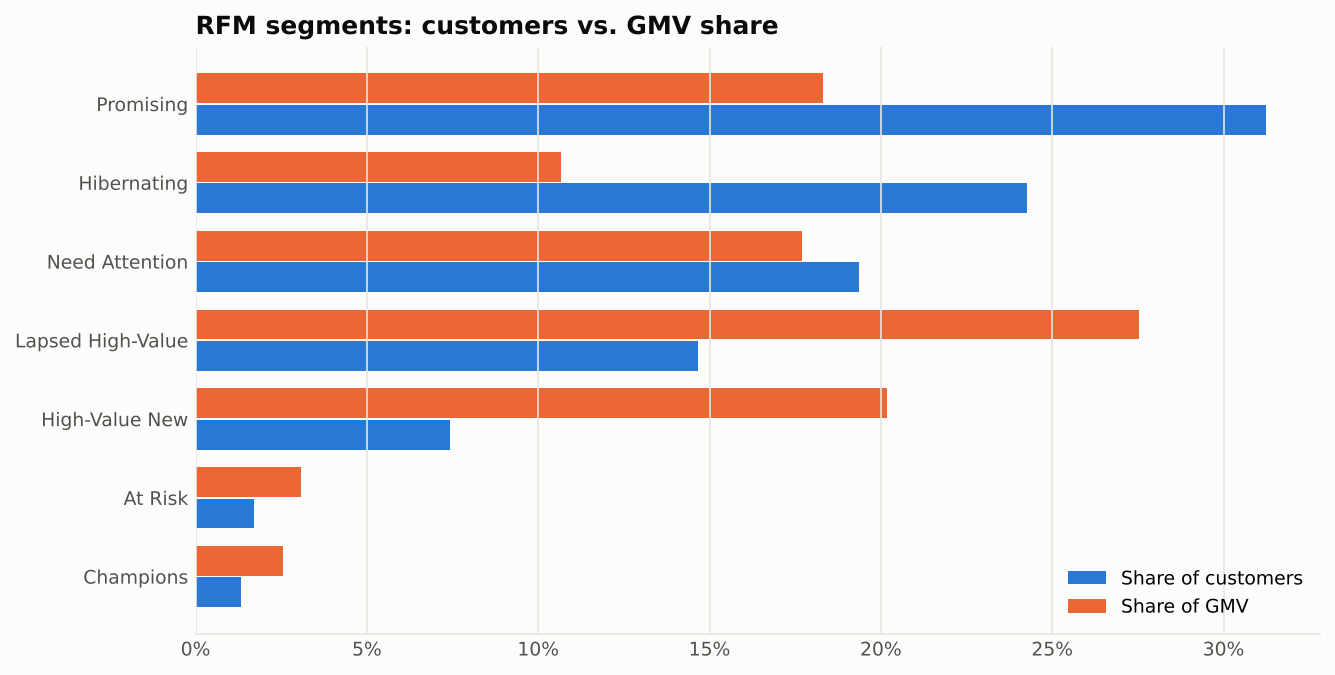

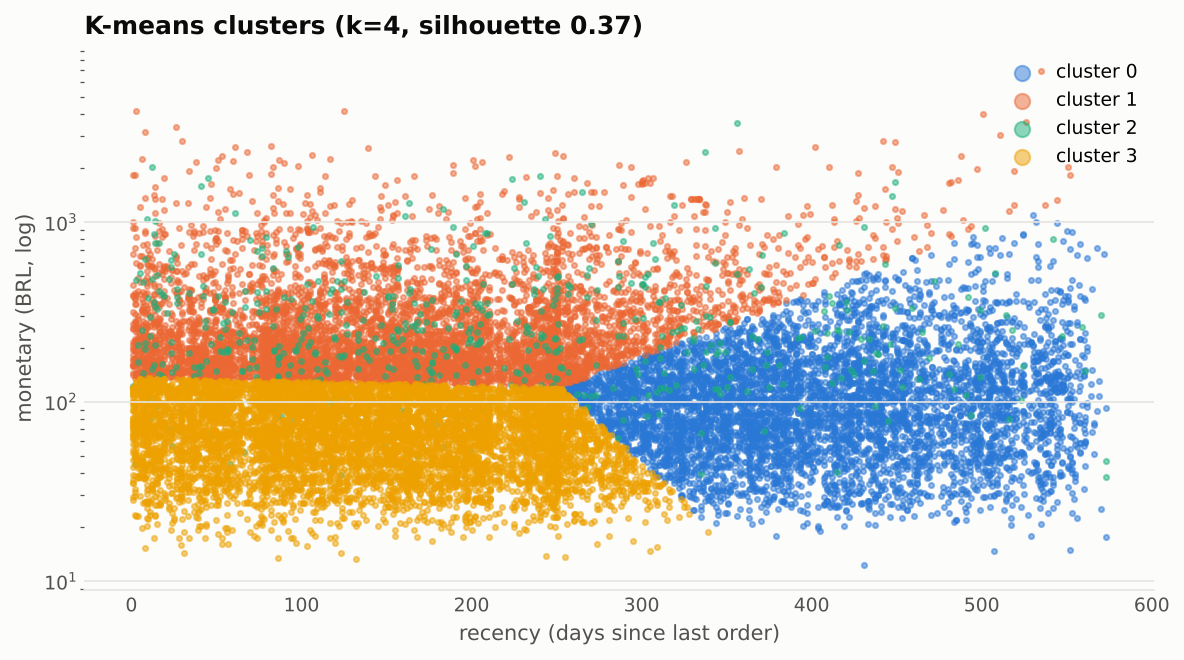

BG/NBD holdout: predicted 741 vs actual 662 repeat purchases (+12.0%)
expected repeat purchases next 12m across the base: 1,824; top decile holds 38% of predicted CLV


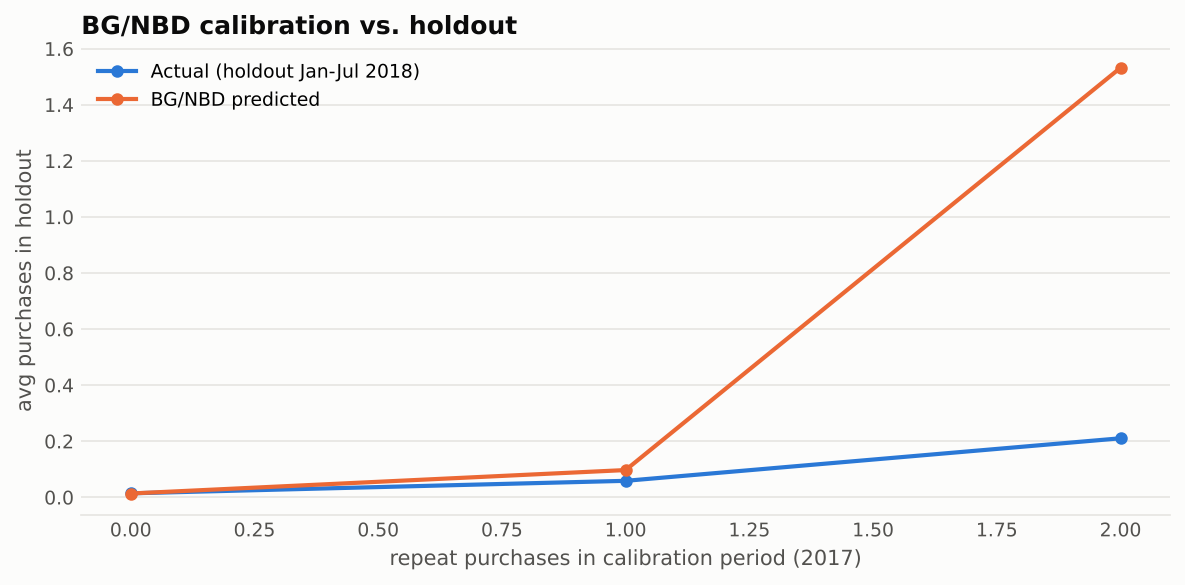

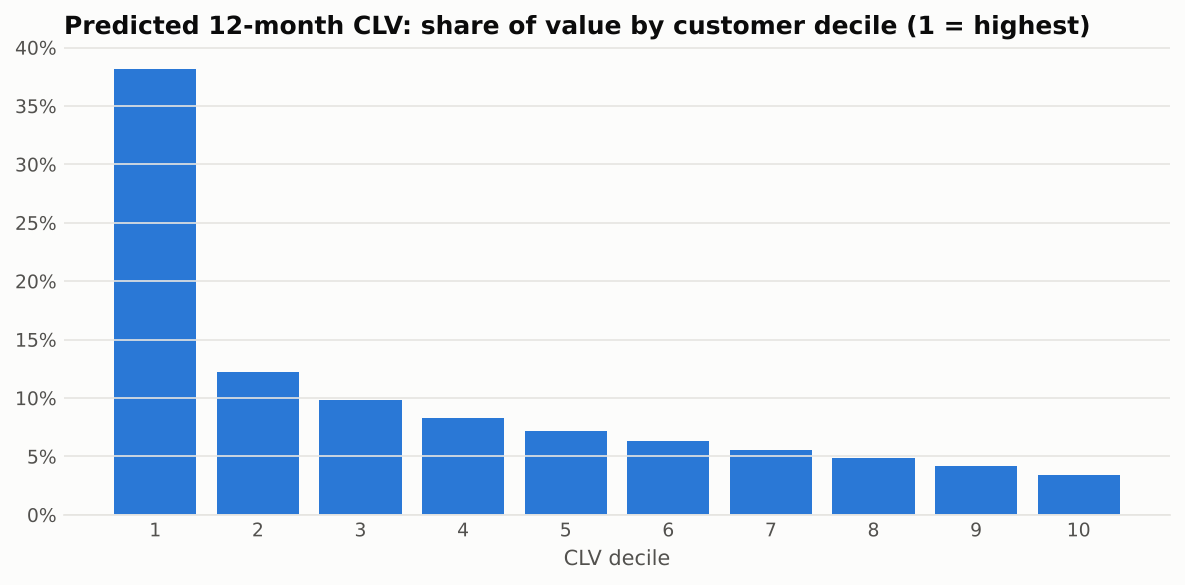

In [5]:
display(tbl("rfm_segment_profile").round(3))
fig("07_rfm_segments"); fig("08_kmeans_clusters")
c = R["clv"]
print(f"BG/NBD holdout: predicted {c['holdout_predicted_purchases']:.0f} vs actual {c['holdout_actual_purchases']:.0f} repeat purchases ({c['holdout_error_pct']:+.1%})")
print(f"expected repeat purchases next 12m across the base: {c['expected_repeat_purchases_12m_total']:,.0f}; top decile holds {c['top_decile_clv_share']:.0%} of predicted CLV")
fig("10_clv_calibration"); fig("09_clv_deciles")

## 5. Delivery performance -> reviews
Lateness is measured against the promised date. The logistic regression controls for basket size, value, distance and multi-seller orders.

,delivery_bucket,orders,share_of_orders,avg_review,detractor_rate,promoter_rate,median_delivery_days
0,A. >1 week early,72254,0.810,4.311,0.090,0.834,9.375
1,B. Early,9969,0.112,4.122,0.115,0.771,16.292
2,C. On the day,1014,0.011,3.948,0.138,0.708,22.229
3,D. 1-3 days late,1644,0.018,3.238,0.336,0.516,24.771
4,E. 4-7 days late,1626,0.018,2.095,0.677,0.224,28.542
5,F. >1 week late,2723,0.031,1.689,0.794,0.115,40.833


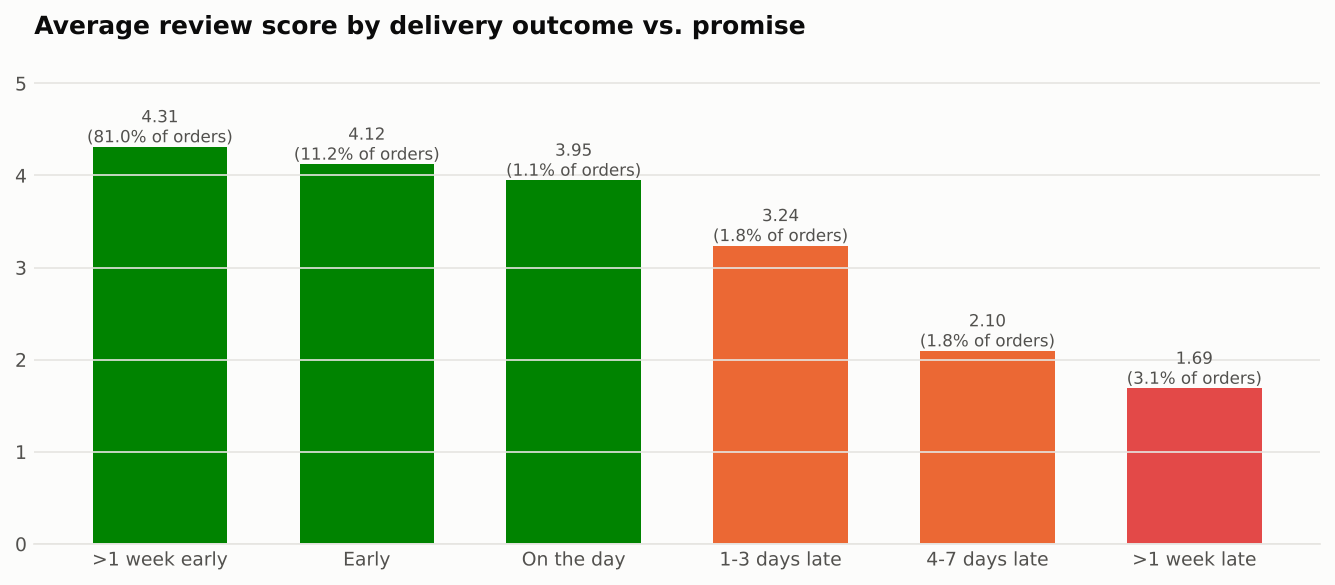

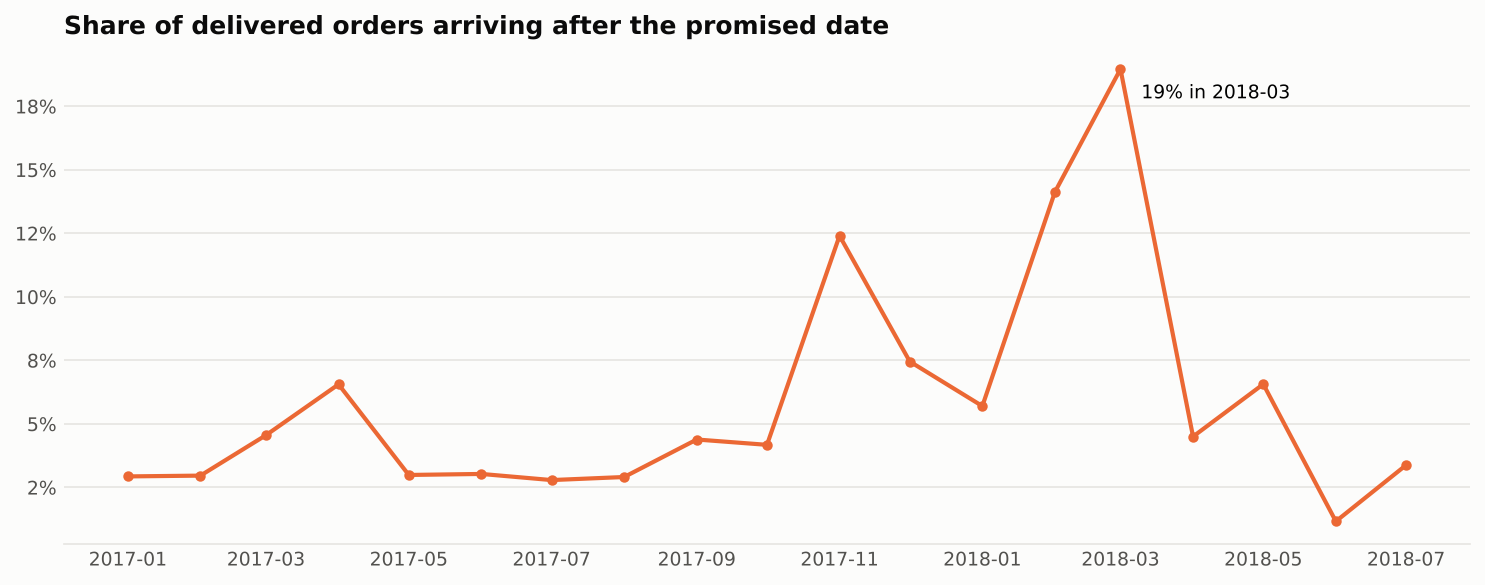

,term,coef,odds_ratio,p_value,ci_low,ci_high
0,Intercept,-3.079,0.046,0.000,0.039,0.054
1,late_1_3,1.339,3.814,0.000,3.398,4.282
2,late_4_7,2.686,14.667,0.000,12.987,16.565
3,late_8p,2.966,19.415,0.000,16.947,22.243
4,delivery_weeks,0.184,1.202,0.000,1.174,1.232
5,multi_seller,1.251,3.494,0.000,3.069,3.977
6,multi_item,1.102,3.011,0.000,2.822,3.213
7,log_gmv,0.061,1.063,0.000,1.027,1.099
8,is_interstate,-0.030,0.970,0.272,0.919,1.024
9,freight_ratio,0.082,1.086,0.035,1.006,1.172


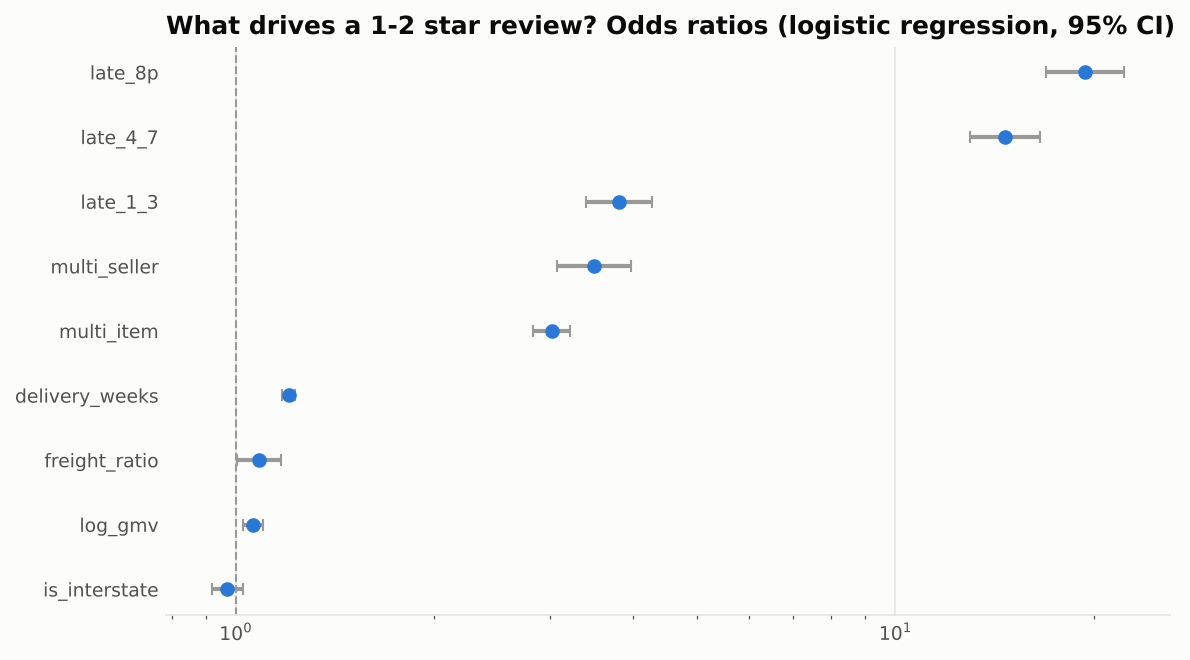

33% of all 1-2 star reviews come from the 6.7% of orders that are late; counterfactual: ~2,880 detractor reviews attributable to lateness


In [6]:
display(query_file(con, "04_delivery_vs_reviews.sql").round(3))
fig("11_review_by_delivery_bucket"); fig("12_late_rate_monthly")
display(tbl("delivery_logit_odds_ratios").round(3))
fig("13_detractor_odds_ratios")
d = R["delivery"]
print(f"{d['late_share_of_all_detractors']:.0%} of all 1-2 star reviews come from the {d['late_rate']:.1%} of orders that are late; "
      f"counterfactual: ~{d['detractors_avoidable_if_on_time']:,.0f} detractor reviews attributable to lateness")

## 6. Late-delivery risk model (checkout-time, point-in-time features, forward split)
Train < Mar-2018, test Mar-Jul 2018. Seller history features only use orders delivered before the order being scored.

{'n_train': 57050, 'n_test': 32802, 'train_late_rate': 0.066, 'test_late_rate': 0.072, 'gbm_auc': 0.735, 'gbm_pr_auc': 0.176, 'gbm_brier': 0.064, 'lr_auc': 0.725, 'lr_pr_auc': 0.161, 'split_date': '2018-03-01', 'top_decile_late_rate': 0.189, 'top_decile_lift': 2.631, 'top_decile_capture': 0.263, 'top2_decile_capture': 0.467, 'threshold_p30': 0.2, 'recall_at_p30': 0.088, 'flag_rate_at_p30': 0.021}


,decile,orders,late,late_rate,lift,cum_capture
0,1,3281,620,0.189,2.631,0.263
1,2,3280,480,0.146,2.037,0.467
2,3,3280,344,0.105,1.460,0.613
3,4,3280,256,0.078,1.087,0.722
4,5,3280,207,0.063,0.879,0.809
5,6,3280,165,0.050,0.700,0.879
6,7,3280,133,0.041,0.565,0.936
7,8,3280,77,0.023,0.327,0.969
8,9,3280,47,0.014,0.200,0.989
9,10,3281,27,0.008,0.115,1.000


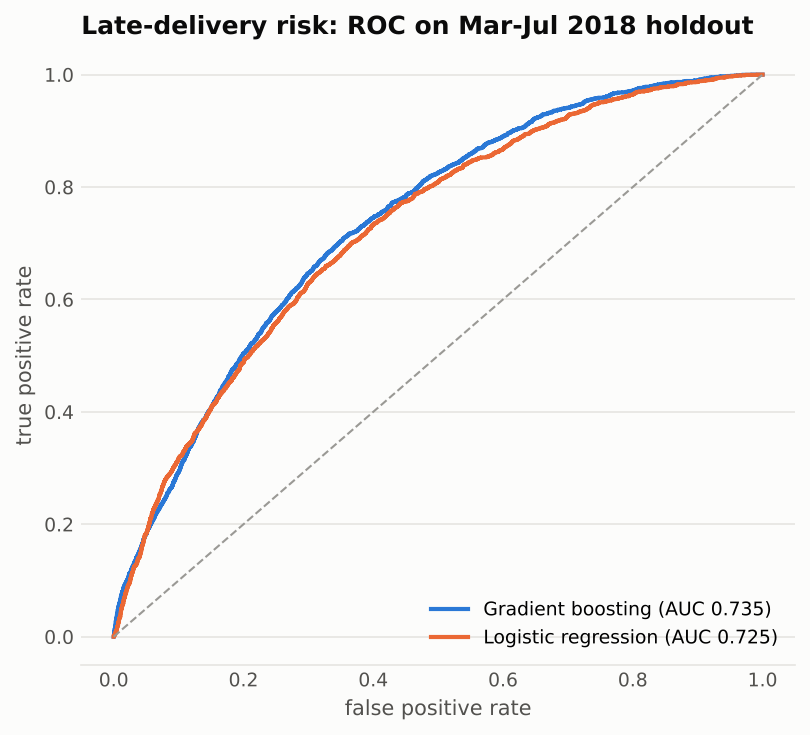

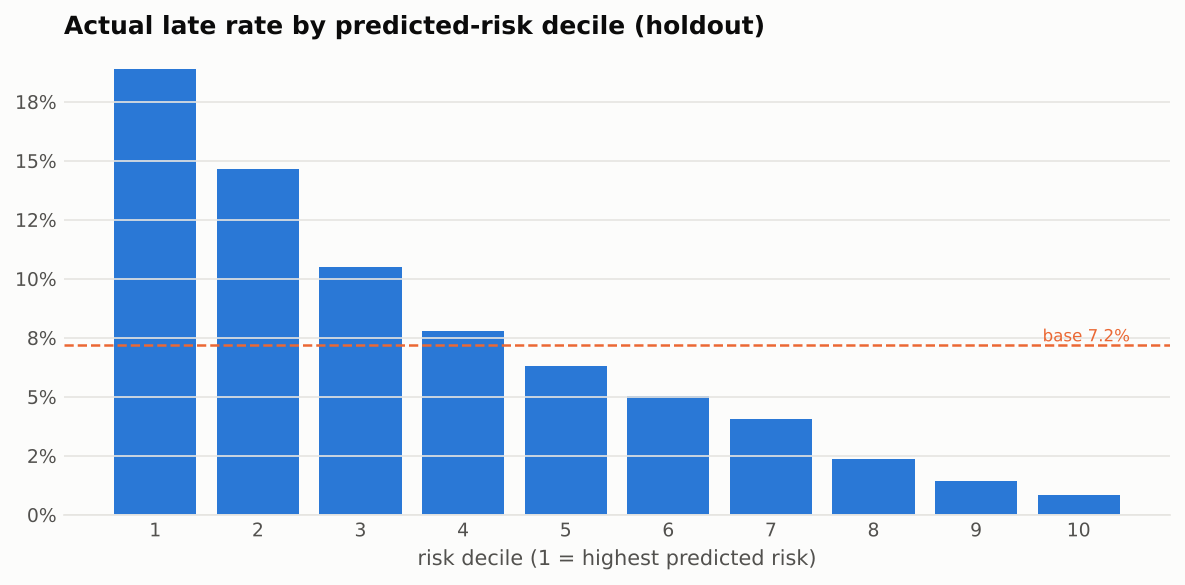

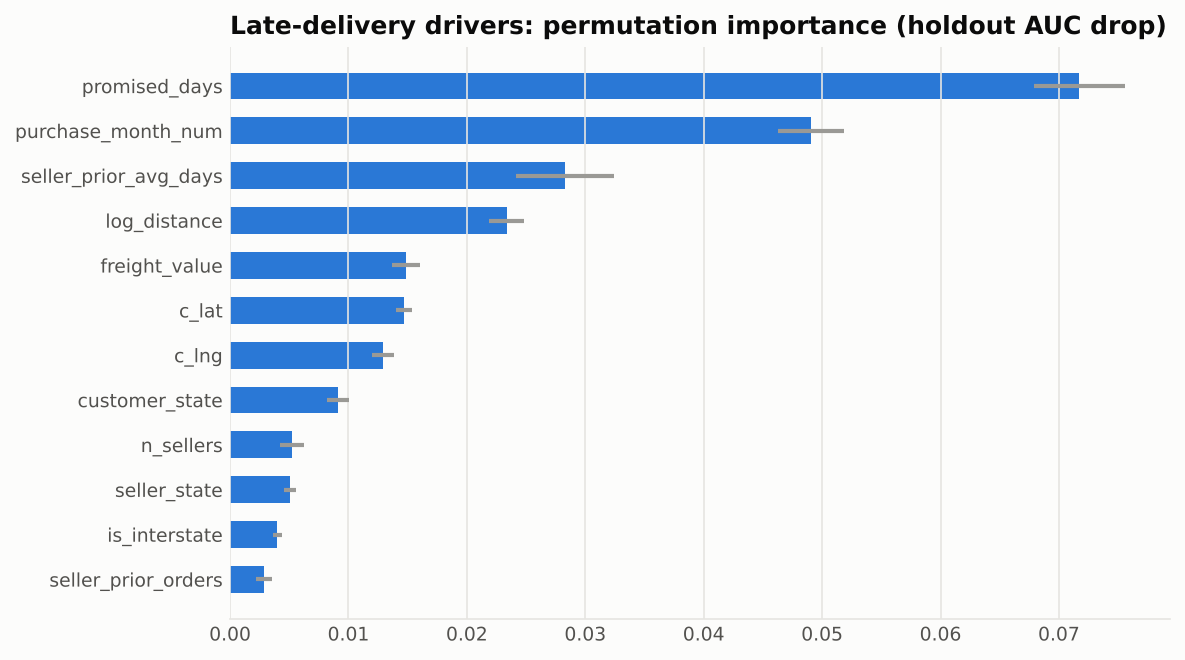

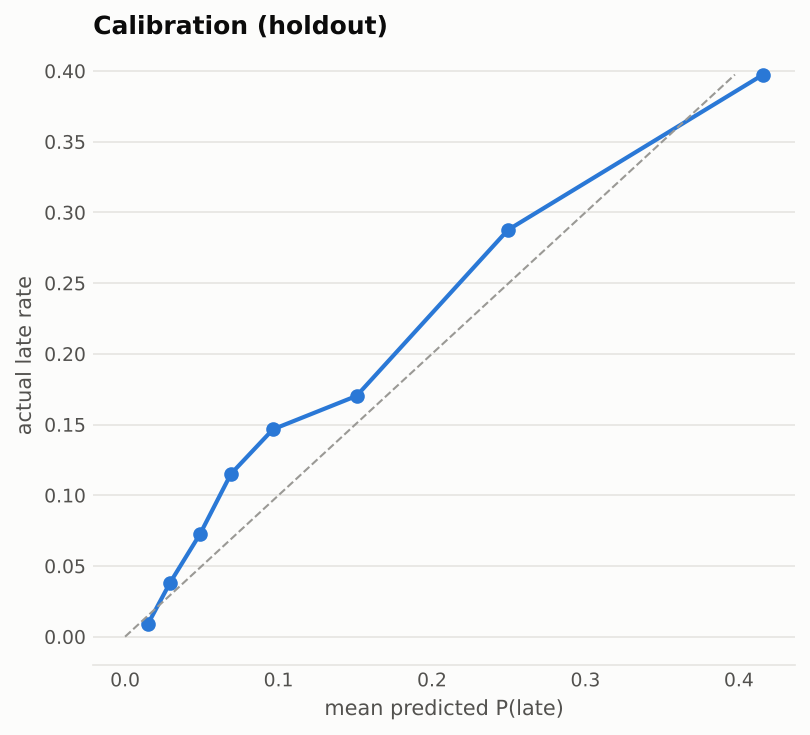

In [7]:
m = R["risk_model"]
print({k: (round(v, 3) if isinstance(v, float) else v) for k, v in m.items() if k != "top_features"})
display(tbl("risk_decile_lift").round(3))
fig("21_risk_roc"); fig("22_risk_lift"); fig("23_risk_importance"); fig("24_risk_calibration")

### 6b. Repeat-purchase propensity - a deliberately reported weak result
Label = true second order within 180 days. First-order attributes barely separate repeaters (AUC ~0.56): retention here is a structural/assortment problem, not a targeting problem.

{'n_train': 36846, 'n_test': 12283, 'base_rate': 0.02, 'gbm_auc': 0.548, 'gbm_pr_auc': 0.028, 'gbm_brier': 0.019, 'lr_auc': 0.57, 'lr_pr_auc': 0.025, 'champion': 'logistic', 'champion_auc': 0.57, 'top_decile_lift': 1.404, 'top2_decile_capture': 0.256, 'top3_decile_capture': 0.384, 'top_features': ['category', 'payment_type', 'delivery_days', 'review_score', 'customer_state']}


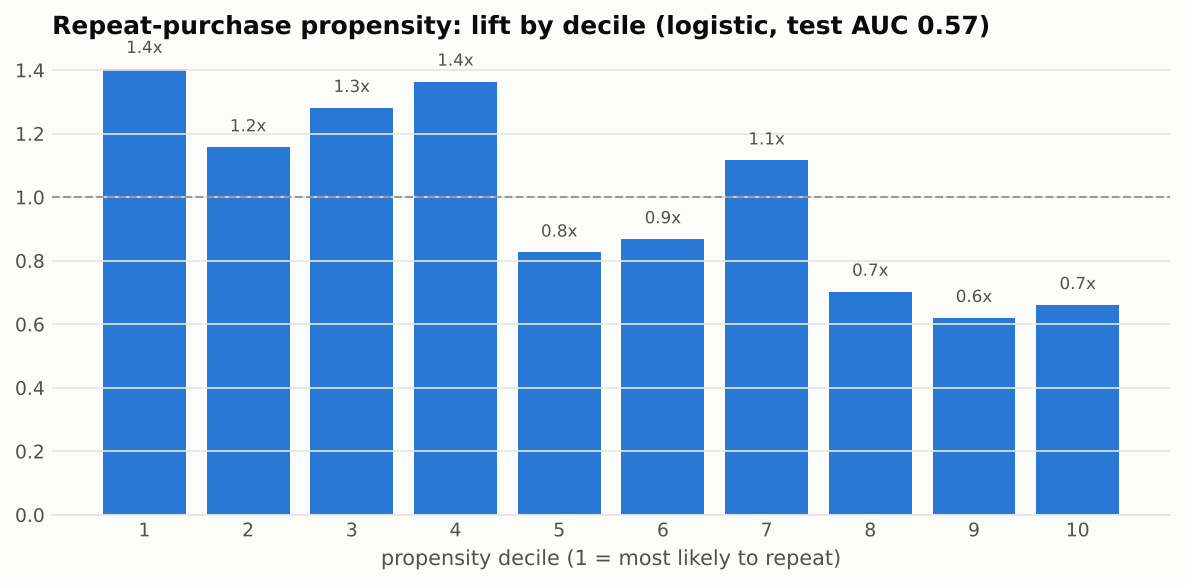

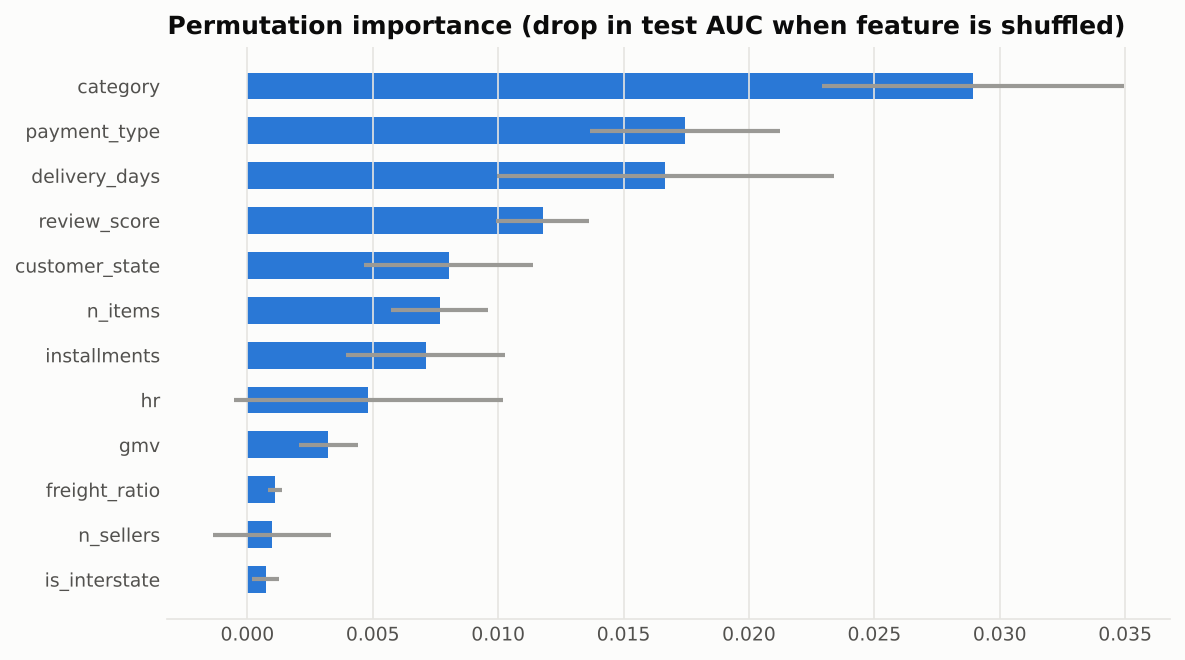

In [8]:
p = R["propensity"]; print({k: (round(v, 3) if isinstance(v, float) else v) for k, v in p.items()})
fig("14_propensity_lift"); fig("15_propensity_importance")

## 7. Seller economics

top 1% of sellers = 25% of GMV, top 10% = 67%, Gini 0.78; 19% of sellers sold exactly once; 19 problem sellers hold R$279K GMV


,seller_id,state,n_orders,gmv,late_rate,avg_review_score,n_reviews,volume_pct,reliability_pct,satisfaction_pct,health_score
0,e882b2a25a10b9c057cc49695f222c19,RJ,57,"53,913.760",0.000,4.579,57,0.987,0.452,0.742,79.200
1,e2a1ac9bf33e5549a2a4f834e70df2f8,SP,5,"15,200.560",0.000,4.800,5,0.933,0.452,0.811,78.200
2,12b9676b00f60f3b700e83af21824c0e,RS,135,"30,342.690",0.008,4.537,134,0.969,0.451,0.727,77.900
3,744dac408745240a2c2528fb1b6028f3,PR,79,"24,385.020",0.012,4.570,79,0.962,0.447,0.737,77.700
4,c3cfdc648177fdbbbb35635a37472c53,PR,278,"49,127.810",0.013,4.469,277,0.984,0.445,0.675,77.200
5,080199a181c46c657dc5aa235411be3b,SP,79,"15,544.880",0.012,4.615,78,0.934,0.447,0.753,76.700
6,d921b68bf747894be13a97ae52b0f386,MG,77,"17,403.810",0.013,4.558,77,0.945,0.446,0.734,76.700
7,ac3508719a1d8f5b7614b798f70af136,RS,103,"15,792.230",0.020,4.604,101,0.937,0.437,0.751,76.500
8,289cdb325fb7e7f891c38608bf9e0962,SP,110,"15,639.290",0.016,4.573,110,0.935,0.442,0.741,76.300
9,6061155addc1e54b4cfb51c1c2a32ad8,SP,28,"16,513.310",0.030,4.643,28,0.941,0.411,0.761,76.300


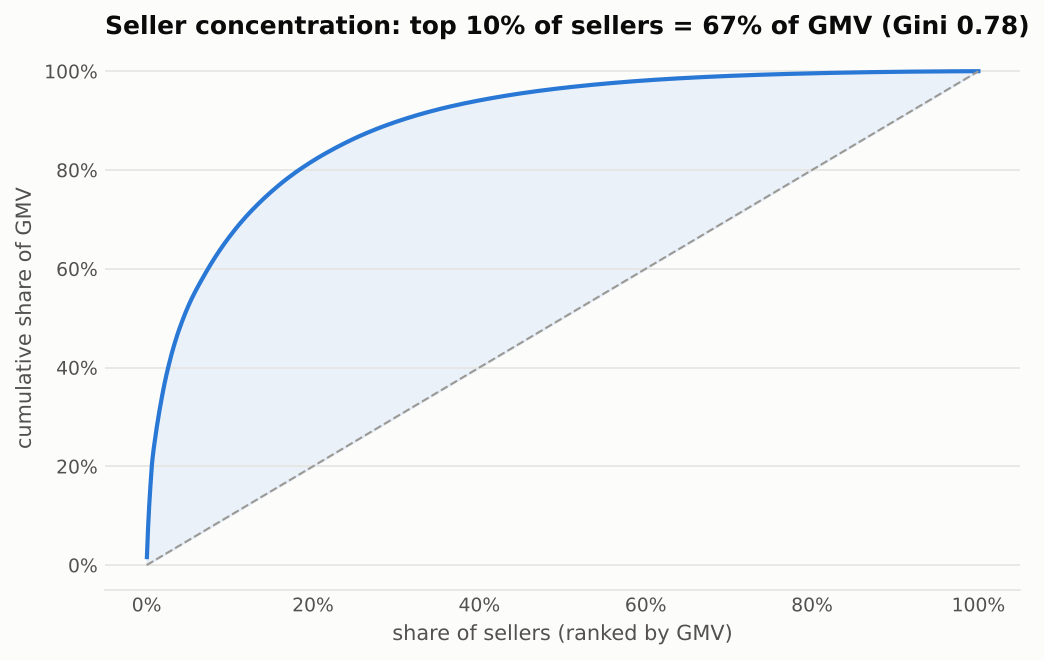

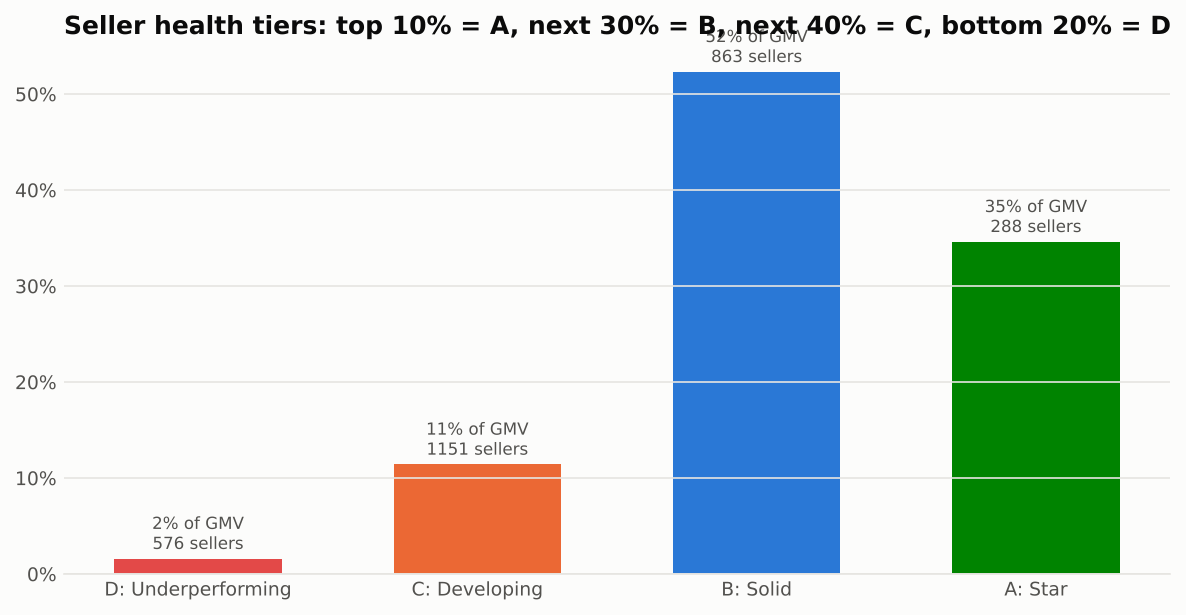

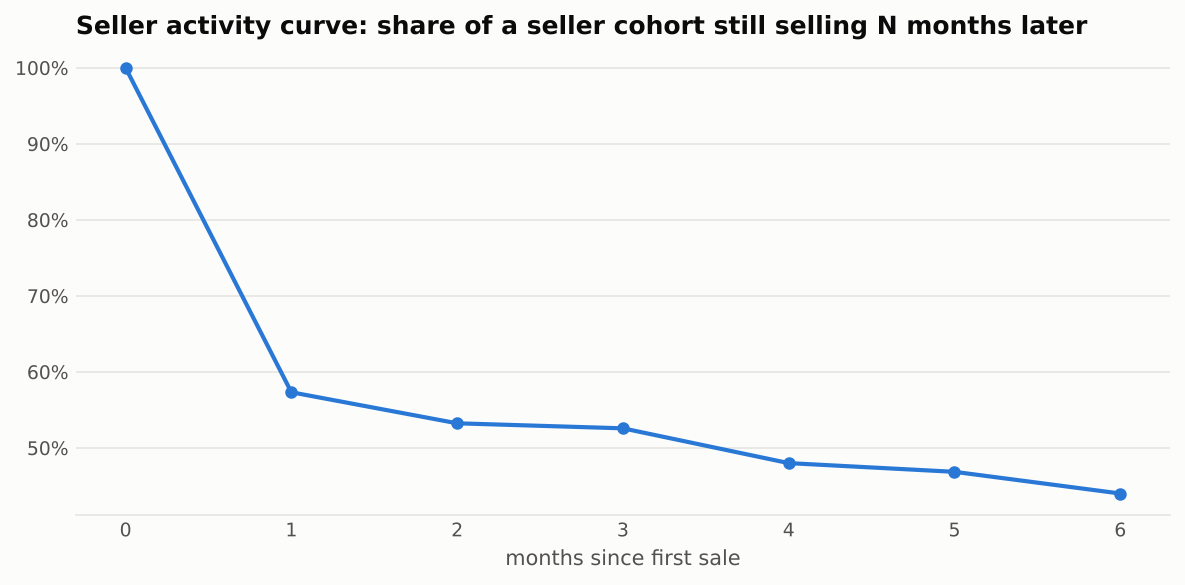

,seller_id,state,n_orders,gmv,late_rate,avg_review,health_score
0,712e6ed8aa4aa1fa65dab41fed5737e4,SC,79,"46,704.130",0.200,3.453,55.600
1,855668e0971d4dfd7bef1b6a4133b41b,SP,307,"39,459.840",0.127,3.760,58.800
2,88460e8ebdecbfecb5f9601833981930,PR,233,"34,856.050",0.169,3.327,55.000
3,7ad32824caee82087b3e2e5f33b1bf32,SP,124,"22,523.060",0.133,3.722,57.100
4,6039e27294dc75811c0d8a39069f52c0,SP,61,"15,335.880",0.225,3.792,55.200
5,431af27f296bc6519d890aa5a05fdb11,SP,117,"15,250.850",0.137,3.774,56.500
6,1ca7077d890b907f89be8c954a02686a,SP,115,"15,001.430",0.150,2.199,50.900
7,54965bbe3e4f07ae045b90b0b8541f52,PR,78,"13,164.840",0.321,2.938,49.600
8,6973a06f484aacf400ece213dbf3d946,SP,92,"11,989.790",0.148,3.591,53.200
9,a49928bcdf77c55c6d6e05e09a9b4ca5,SP,98,"10,574.250",0.212,2.953,48.900


In [9]:
s = R["sellers"]
print(f"top 1% of sellers = {s['top1pct_gmv_share']:.0%} of GMV, top 10% = {s['top10pct_gmv_share']:.0%}, Gini {s['gini']:.2f}; "
      f"{s['sellers_single_order_share']:.0%} of sellers sold exactly once; {s['problem_sellers']} problem sellers hold R${s['problem_sellers_gmv']/1e3:,.0f}K GMV")
display(query_file(con, "11_seller_health.sql").head(10).round(3))
fig("16_seller_concentration"); fig("17_seller_tiers"); fig("18_seller_activity_curve")
display(tbl("seller_problem_list")[["seller_id","state","n_orders","gmv","late_rate","avg_review","health_score"]].round(3))

## 8. Seller acquisition funnel (B2B marketing)
MQL -> closed deal -> activated seller -> realised GMV, by channel. Judging channels on GMV per lead instead of close rate changes the ranking.

,origin,mqls,closed_deals,activated_sellers,close_rate,activation_rate,gmv,gmv_per_mql,median_days_to_close,median_days_to_first_sale
0,unknown,1159,193.000,85.000,0.167,0.440,"240,160.890",207.214,11.000,42.000
1,paid_search,1586,195.000,101.000,0.123,0.518,"182,000.060",114.754,15.000,44.000
2,organic_search,2296,271.000,113.000,0.118,0.417,"235,956.580",102.769,14.000,45.000
3,referral,284,24.000,9.000,0.085,0.375,"19,687.840",69.323,18.500,29.000
4,other,150,4.000,2.000,0.027,0.500,"8,766.630",58.444,9.000,55.500
5,direct_traffic,499,56.000,31.000,0.112,0.554,"27,549.800",55.210,10.000,49.000
6,social,1350,75.000,31.000,0.056,0.413,"51,363.470",38.047,30.000,43.000
7,email,493,15.000,6.000,0.030,0.400,"9,122.410",18.504,21.000,52.000
8,display,118,6.000,2.000,0.051,0.333,"1,207.950",10.237,8.500,80.500
9,other_publicities,65,3.000,0.000,0.046,0.000,0.000,0.000,35.000,NaN


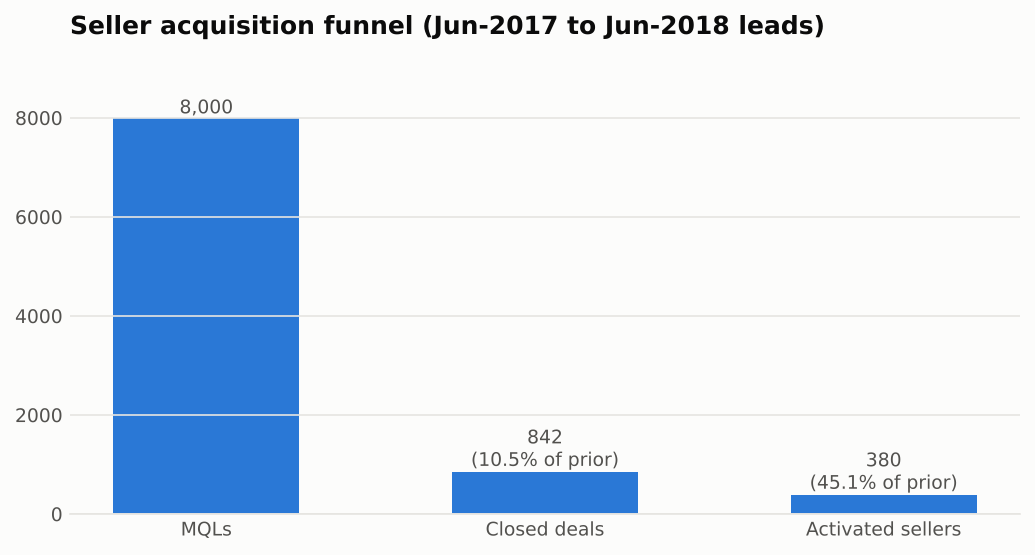

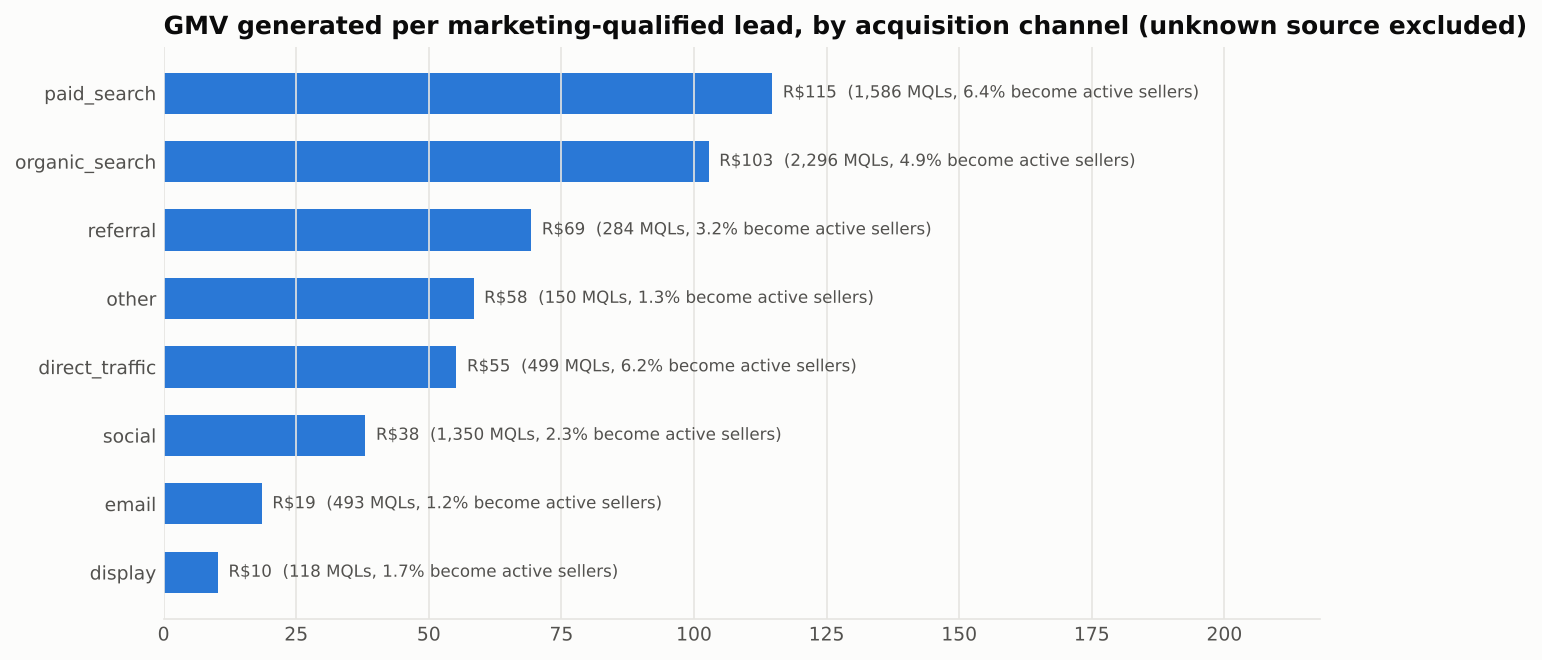

,business_segment,deals,activated,gmv,activation_rate,gmv_per_deal
0,watches,8,3,"126,204.310",0.380,"15,775.540"
1,health_beauty,93,45,"105,026.770",0.480,"1,129.320"
2,household_utilities,71,44,"63,119.260",0.620,889.000
3,audio_video_electronics,64,31,"56,900.890",0.480,889.080
4,home_decor,105,44,"54,304.490",0.420,517.190
5,small_appliances,12,7,"49,500.700",0.580,"4,125.060"
6,pet,30,17,"45,894.060",0.570,"1,529.800"
7,construction_tools_house_garden,69,32,"41,045.150",0.460,594.860


,sr_id,deals,activated,gmv,median_days_to_close,activation_rate,gmv_per_deal
0,4ef15afb4b2723d8f3d81e51ec7afefe,133,75,"116,697.240",11.000,0.560,877.420
1,d3d1e91a157ea7f90548eef82f1955e3,82,41,"55,424.270",10.500,0.500,675.910
2,6565aa9ce3178a5caf6171827af3a9ba,74,36,"56,045.320",11.500,0.490,757.370
3,85fc447d336637ba1df43e793199fbc8,64,32,"46,464.960",10.000,0.500,726.020
4,495d4e95a8cf8bbf8b432b612a2aa328,63,29,"38,387.580",16.000,0.460,609.330
5,2695de1affa7750089c0455f8ce27021,59,21,"45,071.400",16.000,0.360,763.920
6,fbf4aef3f6915dc0c3c97d6812522f6a,59,30,"36,747.410",10.000,0.510,622.840
7,de63de0d10a6012430098db33c679b0b,53,18,"30,515.910",15.000,0.340,575.770


In [10]:
display(query_file(con, "06_funnel_by_channel.sql").round(3))
fig("20_funnel_stages"); fig("19_funnel_gmv_per_mql")
display(tbl("funnel_by_segment").head(8).round(2)); display(tbl("funnel_by_sales_rep").head(8).round(2))

## 9. Geography

,region,orders,gmv,avg_delivery_days,late_rate,freight_ratio,avg_review,gmv_share
0,Southeast,63222,"9,495,828.060",13.263,0.082,0.306,4.046,0.642
1,South,13252,"2,147,116.020",14.384,0.063,0.334,4.118,0.145
2,Northeast,8912,"1,786,182.690",21.021,0.143,0.469,3.878,0.121
3,Center-West,5424,"963,106.730",15.798,0.069,0.345,4.075,0.065
4,North,1770,"390,661.600",23.873,0.067,0.507,3.998,0.026


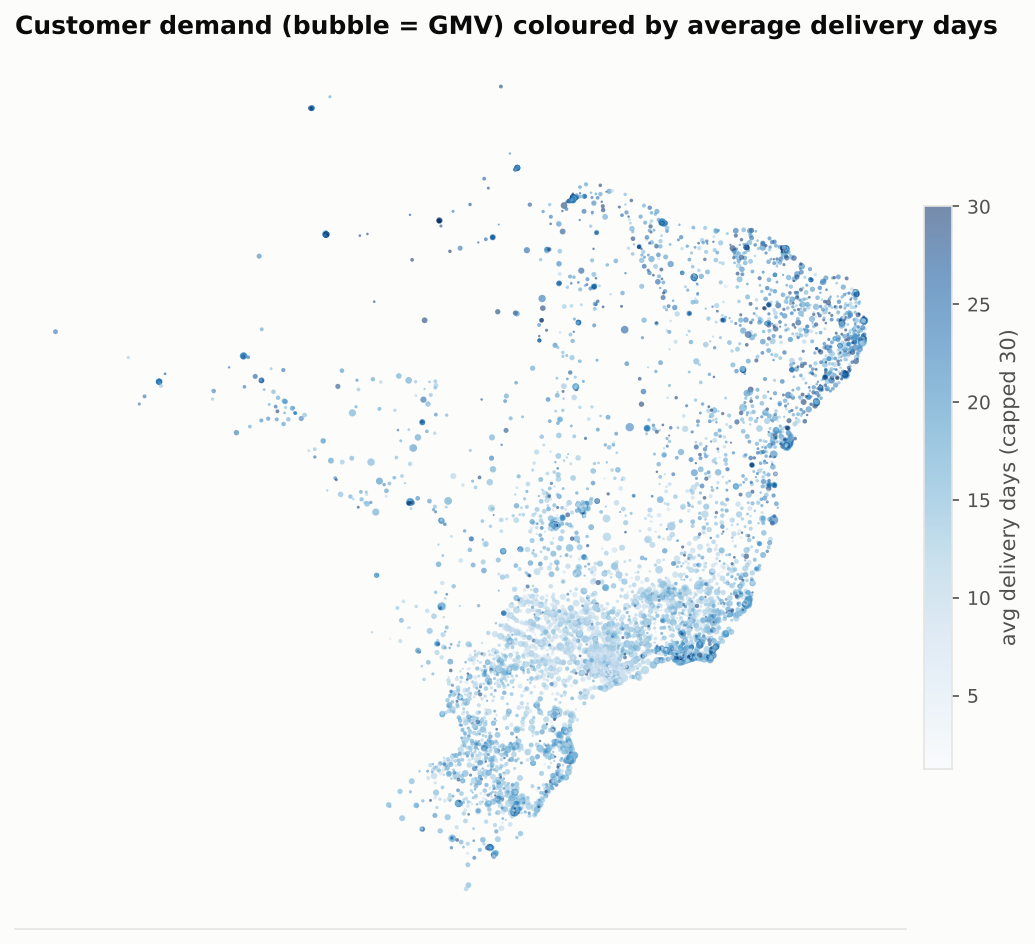

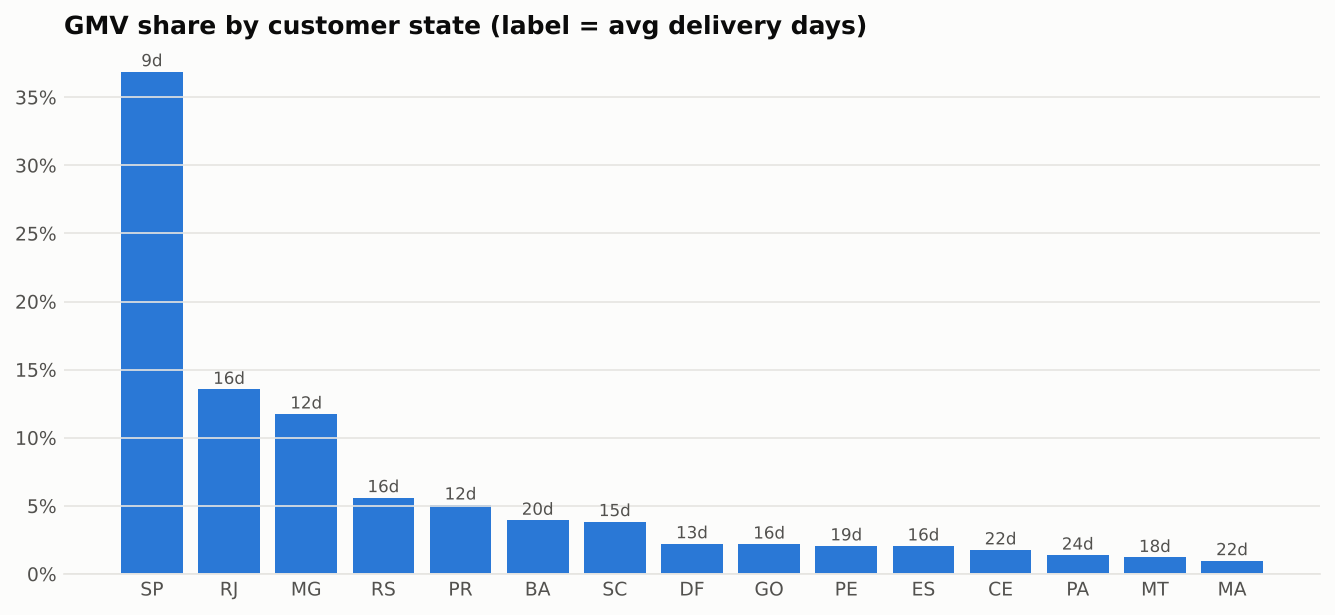

,seller_state,customer_state,orders,gmv,avg_delivery_days,late_rate,freight_ratio,avg_review
0,SP,SP,28795,"3,772,874.270",8.122,0.041,0.239,4.192
1,SP,RJ,7963,"1,235,904.630",16.704,0.147,0.327,3.795
2,SP,MG,7107,"1,053,175.910",12.634,0.055,0.336,4.099
3,SP,RS,3437,"504,346.230",16.488,0.069,0.353,4.076
4,SP,PR,2957,"447,194.200",13.062,0.046,0.354,4.142
5,PR,SP,2770,"494,340.400",11.334,0.029,0.260,4.222
6,MG,SP,2452,"363,936.160",11.129,0.037,0.331,4.201
7,SP,BA,2263,"371,603.990",20.214,0.136,0.391,3.798
8,SP,SC,2244,"345,853.800",16.141,0.099,0.345,3.994
9,MG,MG,1451,"201,990.010",8.867,0.025,0.250,4.305


In [11]:
display(tbl("geo_region").round(3)); fig("26_geo_bubble_map"); fig("27_geo_state_gmv")
display(query_file(con, "09_interstate_friction.sql").head(10).round(3))

## 10. Weekly GMV forecast with a rolling-origin backtest
Three models, six origins, 8-week horizon. The honest result: with 84 weeks and a 2018 plateau, a last-4-week mean is hard to beat.

,model,wape_mean,wape_median,bias_mean
0,naive_last4w_mean,0.143,0.162,0.014
1,holt_damped,0.170,0.155,0.085
2,sarima_log,0.245,0.216,0.235


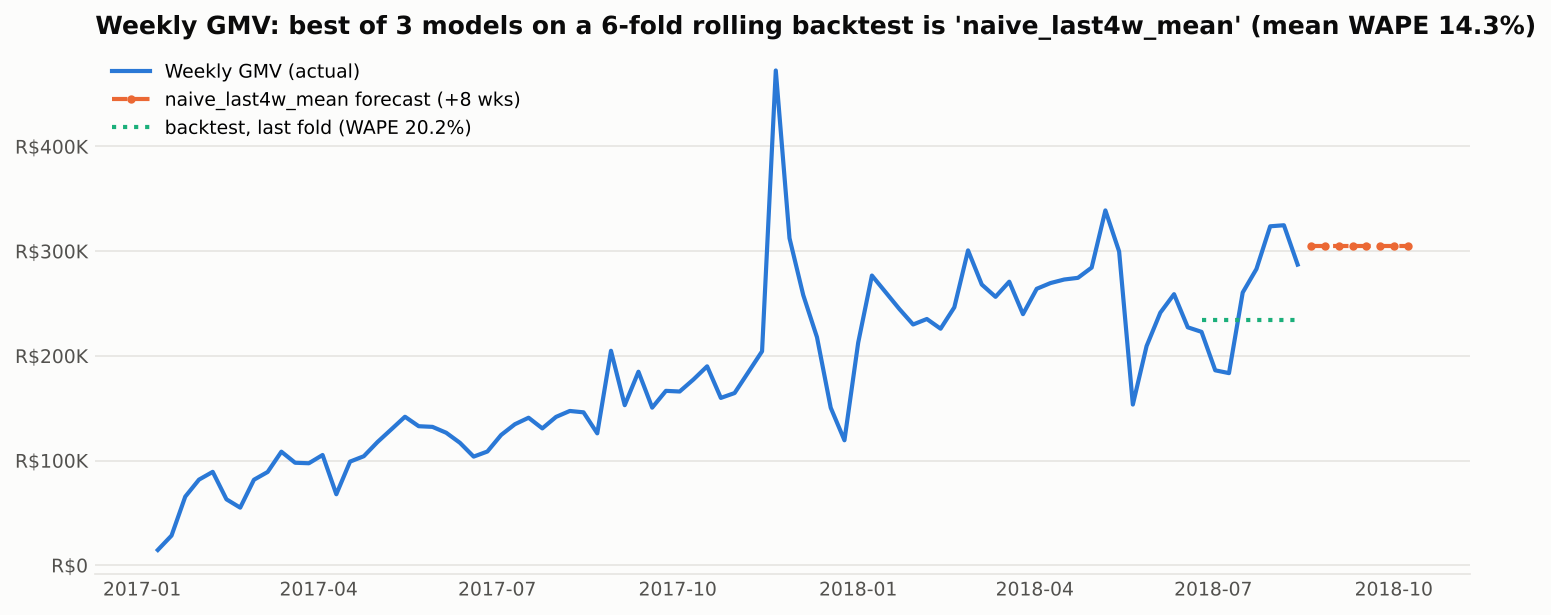

,week,naive_last4w_mean,holt_damped,sarima_log
0,2018-08-20,"304,673.000","299,922.000","297,555.000"
1,2018-08-27,"304,673.000","301,825.000","305,176.000"
2,2018-09-03,"304,673.000","303,707.000","311,434.000"
3,2018-09-10,"304,673.000","305,570.000","317,051.000"
4,2018-09-17,"304,673.000","307,412.000","322,389.000"
5,2018-09-24,"304,673.000","309,235.000","327,628.000"
6,2018-10-01,"304,673.000","311,039.000","332,860.000"
7,2018-10-08,"304,673.000","312,823.000","338,129.000"


In [12]:
display(tbl("forecast_backtest_summary").round(4)); fig("25_weekly_forecast"); display(tbl("forecast_next_8_weeks").round(0))

## 11. Recommendations and how to test them
1. **Proactive delay management** using the risk model's top two deciles (captures ~48% of late orders).
2. **Seller SLA and A-D tiering**; remediate or delist the problem-seller list.
3. **Shift B2B acquisition spend from social to search** on GMV-per-lead; fix the 14% of leads with unknown source first.
4. **Win-back the Lapsed High-Value segment** with a holdout-measured voucher; stop re-acquiring Hibernating customers.
5. **Reduce multi-seller basket failures** (second-largest review driver).

Each maps to a pre-registered test with sample size and duration at the 2018 run-rate:

In [13]:
display(tbl("experiment_plan")[["test","metric","baseline","mde_relative","n_per_arm","weeks_to_run","feasible"]].round(3))

,test,metric,baseline,mde_relative,n_per_arm,weeks_to_run,feasible
0,T1 Proactive delay notification,detractor rate among flagged orders,0.178,-0.250,1037,8.000,True
1,T2 Seller shipping SLA (handling <= 2 days),late delivery rate,0.072,-0.200,4586,11.000,True
2,T3 Win-back campaign for Lapsed High-Value,60-day repurchase rate,0.012,0.500,6379,NaN,True
3,T4 Free-shipping threshold (R$150),average order value,165.642,0.050,11926,17.000,False


---
*Data: Olist Brazilian E-Commerce Public Dataset + Marketing Funnel dataset (Kaggle, CC BY-NC-SA 4.0). Pipeline: dbt-duckdb, pandas, scikit-learn, statsmodels, lifetimes, Plotly, Tableau Hyper API.*